# From rfft2 to the real matrix $Z$: a Fourier 2SDR walkthrough

This notebook is a companion to Section 2 and Supplementary Section S1 of
**Fourier-Domain Two-Stage Dimension Reduction for Image Applications**.
It is designed for a reader who wants to use Fourier 2SDR before mastering
every parity and conjugacy calculation.

By the end, you will be able to:

1. reproduce the Supplement's $4\times4$ calculation by hand and in code;
2. verify that the executed route equals $Z=Q_h^T XQ_w$;
3. check phase retention, Parseval norm preservation, and exact inversion;
4. repeat the checks on a synthetic 70S particle used in the paper; and
5. see how a batch of $Z$ matrices enters a small fixed-rank 2SDR fit.


## Prerequisites and scope

Run Jupyter from the repository root after installing the optional dependencies:

    python -m pip install -e '.[experiments,notebook]'

The $4\times4$ and random-shape sections need no external data. The 70S
sections use the verified project-generated stacks:

    ./data/fetch_data.sh 70s

This downloads about 1.9 GB and requires the GitHub CLI and access to this repository's
datasets-v1 release. The notebook never downloads data automatically.

The final 2SDR fit is deliberately small and uses fixed ranks $(4,4,4)$.
It illustrates the data path; it is not a reproduction of the paper's
rank-selection experiments or a new scientific comparison.


In [1]:
from __future__ import annotations

import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image

from fourier_2sdr import (
    fit_2sdr,
    real_fourier_inverse,
    real_fourier_transform,
)
from fourier_2sdr.fourier import real_fourier_basis
from fourier_2sdr.io import mrc_header

torch.set_printoptions(precision=6, linewidth=110, sci_mode=False)
np.set_printoptions(precision=6, linewidth=110, suppress=True)
torch.manual_seed(20260818)

start_directory = Path.cwd().resolve()
REPO_ROOT = next(
    (
        candidate
        for candidate in (start_directory, *start_directory.parents)
        if (candidate / "pyproject.toml").is_file()
        and (candidate / "src" / "fourier_2sdr").is_dir()
    ),
    None,
)
if REPO_ROOT is None:
    raise RuntimeError(
        "Could not locate the repository root above the kernel cwd."
    )
os.chdir(REPO_ROOT)

print("Repository root located")
print(f"PyTorch: {torch.__version__}")


Repository root located
PyTorch: 2.11.0+cu128


## 1. The two descriptions of the same coordinates

The mathematical construction is

$$Z=Q_h^T XQ_w,$$

where each $Q_d$ is a real orthogonal Fourier basis ordered as DC,
cosine, sine, and (for even $d$) Nyquist coordinates.

The implementation does **not** build dense $Q_h$ and $Q_w$. It performs
one orthonormal rfft2, then applies fixed blocks that remove Hermitian
redundancy. The identity $Q_d^T=C_dF_d$ says that the construction and
computation must agree.


In [2]:
sqrt2 = 2.0**0.5

F4 = 0.5 * torch.tensor(
    [
        [1, 1, 1, 1],
        [1, -1j, -1, 1j],
        [1, -1, 1, -1],
        [1, 1j, -1, -1j],
    ],
    dtype=torch.complex128,
)
Q4 = real_fourier_basis(4, dtype=torch.float64)
C4 = torch.tensor(
    [
        [1, 0, 0, 0],
        [0, 1 / sqrt2, 0, 1 / sqrt2],
        [0, 1j / sqrt2, 0, -1j / sqrt2],
        [0, 0, 1, 0],
    ],
    dtype=torch.complex128,
)

torch.testing.assert_close(
    C4 @ F4, Q4.T.to(torch.complex128), atol=1e-14, rtol=1e-14
)
torch.testing.assert_close(
    Q4.T @ Q4, torch.eye(4, dtype=torch.float64), atol=1e-14, rtol=1e-14
)

print("Q4 =")
print(Q4)
print("\nmax |C4 F4 - Q4.T| =", float((C4 @ F4 - Q4.T).abs().max()))


Q4 =
tensor([[ 0.500000,  0.707107,  0.000000,  0.500000],
        [ 0.500000,  0.000000,  0.707107, -0.500000],
        [ 0.500000, -0.707107,  0.000000,  0.500000],
        [ 0.500000, -0.000000, -0.707107, -0.500000]], dtype=torch.float64)

max |C4 F4 - Q4.T| = 1.29893408435324e-16


### One axis

For $x=(4,1,2,3)^T$, the Supplement gives

$$F_4x=(5,1+i,1,1-i)^T,$$
$$Q_4^Tx=(5,\sqrt2,-\sqrt2,1)^T.$$

The cosine coordinate is $\sqrt2\,\mathrm{Re}(F_4x)_1$ and the sine
coordinate is $-\sqrt2\,\mathrm{Im}(F_4x)_1$. The sign matters:
replacing Fourier coefficients by magnitudes would discard this phase
information.


In [3]:
x = torch.tensor([4.0, 1.0, 2.0, 3.0], dtype=torch.float64)
y = torch.tensor([1.0, 4.0, 3.0, 2.0], dtype=torch.float64)

Fx = torch.fft.fft(x, norm="ortho")
Qtx = Q4.T @ x
Qty = Q4.T @ y

expected_Qtx = torch.tensor(
    [5.0, sqrt2, -sqrt2, 1.0], dtype=torch.float64
)
expected_Qty = torch.tensor(
    [5.0, -sqrt2, sqrt2, -1.0], dtype=torch.float64
)
torch.testing.assert_close(
    Fx, F4 @ x.to(torch.complex128), atol=1e-14, rtol=1e-14
)
torch.testing.assert_close(Qtx, expected_Qtx, atol=1e-14, rtol=1e-14)
torch.testing.assert_close(Qty, expected_Qty, atol=1e-14, rtol=1e-14)
torch.testing.assert_close(
    x.square().sum(), Qtx.square().sum(), atol=1e-14, rtol=1e-14
)

print("F4 x  =", Fx)
print("Q4.T x=", Qtx)
print("Q4.T y=", Qty)
print(
    "squared norm before/after =",
    float(x.square().sum()),
    float(Qtx.square().sum()),
)


F4 x  = tensor([5.+0.j, 1.+1.j, 1.+0.j, 1.-1.j], dtype=torch.complex128)
Q4.T x= tensor([ 5.000000,  1.414214, -1.414214,  1.000000], dtype=torch.float64)
Q4.T y= tensor([ 5.000000, -1.414214,  1.414214, -1.000000], dtype=torch.float64)
squared norm before/after = 30.0 30.0


## 2. The complete $4\times4$ image

Set $X=xy^T$. Its stored rfft2 half spectrum has shape $4\times3$.
Stacking all real and imaginary parts would give 24 real numbers, but
Hermitian symmetry forces zeros and duplicates. The block construction
keeps exactly the original $D=16$ independent real coordinates.


In [4]:
X = torch.outer(x, y)
Xh = torch.fft.rfft2(X, norm="ortho")
middle = C4 @ Xh

Z_manual = torch.empty((4, 4), dtype=torch.float64)
Z_manual[:, 0] = middle[:, 0].real
Z_manual[:, 1] = sqrt2 * middle[:, 1].real
Z_manual[:, 2] = -sqrt2 * middle[:, 1].imag
Z_manual[:, 3] = middle[:, 2].real

Z_dense = Q4.T @ X @ Q4
Z_api = real_fourier_transform(X)

torch.testing.assert_close(
    Z_manual, Z_dense, atol=2e-14, rtol=2e-14
)
torch.testing.assert_close(Z_api, Z_dense, atol=2e-14, rtol=2e-14)

print("X =")
print(X)
print("\nrfft2(X) =")
print(Xh)
print("\nZ =")
print(Z_api)
print(
    "\nmax manual-vs-dense error =",
    float((Z_manual - Z_dense).abs().max()),
)
print(
    "max API-vs-dense error    =",
    float((Z_api - Z_dense).abs().max()),
)


X =
tensor([[ 4., 16., 12.,  8.],
        [ 1.,  4.,  3.,  2.],
        [ 2.,  8.,  6.,  4.],
        [ 3., 12.,  9.,  6.]], dtype=torch.float64)

rfft2(X) =
tensor([[25.+0.j, -5.-5.j, -5.+0.j],
        [ 5.+5.j,  0.-2.j, -1.-1.j],
        [ 5.+0.j, -1.-1.j, -1.+0.j],
        [ 5.-5.j, -2.+0.j, -1.+1.j]], dtype=torch.complex128)

Z =
tensor([[25.000000, -7.071068,  7.071068, -5.000000],
        [ 7.071068, -2.000000,  2.000000, -1.414214],
        [-7.071068,  2.000000, -2.000000,  1.414214],
        [ 5.000000, -1.414214,  1.414214, -1.000000]], dtype=torch.float64)

max manual-vs-dense error = 8.881784197001252e-16
max API-vs-dense error    = 8.881784197001252e-16


In [5]:
weights = torch.tensor([1.0, 2.0, 1.0], dtype=torch.float64)
norm_x = X.square().sum()
norm_z = Z_api.square().sum()
weighted_half_norm = (Xh.abs().square() * weights).sum()
X_roundtrip = real_fourier_inverse(Z_api)

torch.testing.assert_close(
    norm_x, torch.tensor(900.0, dtype=torch.float64), atol=1e-12, rtol=0
)
torch.testing.assert_close(norm_z, norm_x, atol=1e-12, rtol=1e-14)
torch.testing.assert_close(
    weighted_half_norm, norm_x, atol=1e-12, rtol=1e-14
)
torch.testing.assert_close(X_roundtrip, X, atol=1e-12, rtol=1e-14)

print(f"raw Re/Im stack size: {2 * Xh.numel()} real numbers")
print(f"independent Z size:    {Z_api.numel()} real coordinates")
print(f"||X||_F^2:             {float(norm_x):.12f}")
print(f"weighted half norm:    {float(weighted_half_norm):.12f}")
print(f"||Z||_F^2:             {float(norm_z):.12f}")
print(
    f"round-trip max error:  "
    f"{float((X_roundtrip - X).abs().max()):.3e}"
)


raw Re/Im stack size: 24 real numbers
independent Z size:    16 real coordinates
||X||_F^2:             900.000000000000
weighted half norm:    900.000000000000
||Z||_F^2:             900.000000000000
round-trip max error:  8.882e-16


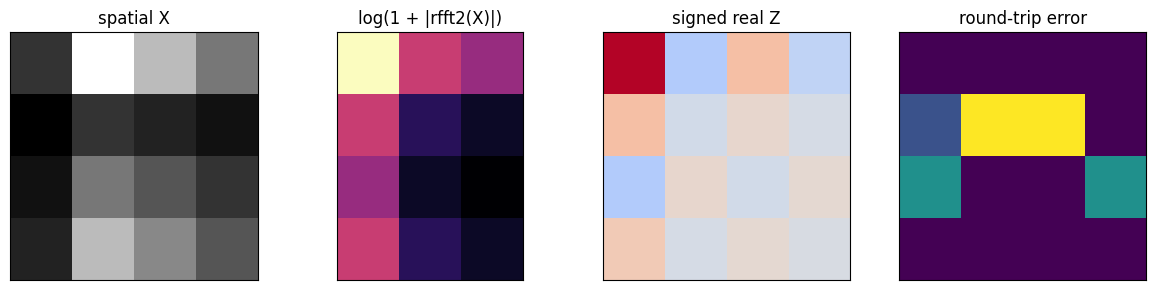

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
axes[0].imshow(X, cmap="gray")
axes[0].set_title("spatial X")
axes[1].imshow(torch.log1p(Xh.abs()), cmap="magma")
axes[1].set_title("log(1 + |rfft2(X)|)")
limit = float(Z_api.abs().max())
axes[2].imshow(Z_api, cmap="coolwarm", vmin=-limit, vmax=limit)
axes[2].set_title("signed real Z")
axes[3].imshow((X_roundtrip - X).abs(), cmap="viridis")
axes[3].set_title("round-trip error")
for axis in axes:
    axis.set_xticks([])
    axis.set_yticks([])
fig.tight_layout()


## 3. Odd and even image sizes

DC and Nyquist bookkeeping differs between odd and even dimensions.
Users of the public transform do not need to implement those branches,
but they should know what must remain true: the output has the original
shape, equals the dense $Q_h^TXQ_w$ construction, preserves norm, and
inverts exactly up to floating-point error.


In [7]:
generator = torch.Generator().manual_seed(20260818)
rows = []
for height, width in ((5, 7), (6, 8), (5, 8), (6, 7)):
    images = torch.randn(
        3, height, width, generator=generator, dtype=torch.float64
    )
    Qh = real_fourier_basis(height, dtype=torch.float64)
    Qw = real_fourier_basis(width, dtype=torch.float64)
    dense = torch.einsum("pa,npq,qb->nab", Qh, images, Qw)
    block = real_fourier_transform(images)
    recovered = real_fourier_inverse(block)
    dense_error = float((block - dense).abs().max())
    inverse_error = float((recovered - images).abs().max())
    parseval_error = float(
        (block.square().sum() - images.square().sum()).abs()
    )
    torch.testing.assert_close(
        block, dense, atol=2e-12, rtol=2e-12
    )
    torch.testing.assert_close(
        recovered, images, atol=2e-12, rtol=2e-12
    )
    torch.testing.assert_close(
        block.square().sum(),
        images.square().sum(),
        atol=2e-11,
        rtol=2e-12,
    )
    rows.append(
        (f"{height}x{width}", dense_error, inverse_error, parseval_error)
    )

print(
    f"{'shape':>8} {'dense error':>15} "
    f"{'inverse error':>15} {'Parseval error':>17}"
)
for shape, dense_error, inverse_error, parseval_error in rows:
    print(
        f"{shape:>8} {dense_error:15.3e} "
        f"{inverse_error:15.3e} {parseval_error:17.3e}"
    )


   shape     dense error   inverse error    Parseval error
     5x7       2.665e-15       1.332e-15         2.842e-14
     6x8       1.638e-15       1.332e-15         2.842e-14
     5x8       1.776e-15       8.882e-16         1.421e-14
     6x7       1.998e-15       6.661e-16         1.421e-14


## 4. Numerical intuition for white noise

An orthogonal change of coordinates maps $N(0,\sigma^2I)$ noise to
$N(0,\sigma^2I)$ noise. The covariance display below is a finite-sample
illustration, not the proof. The proof is the one-line identity

$$\operatorname{Cov}(Q^T\varepsilon)
  =Q^T(\sigma^2I)Q=\sigma^2I.$$


max variance error:      0.0214
max cross-covariance:    0.0179


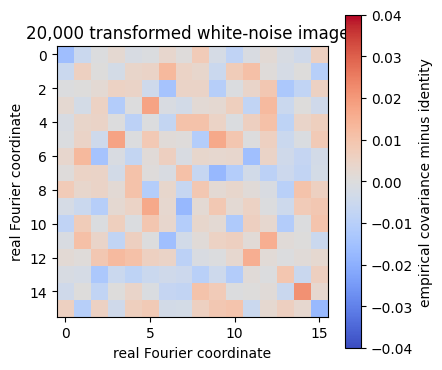

In [8]:
noise = torch.randn(
    20_000, 4, 4, generator=generator, dtype=torch.float64
)
noise_z = real_fourier_transform(noise).reshape(len(noise), -1)
empirical_covariance = torch.cov(noise_z.T)
identity = torch.eye(16, dtype=torch.float64)
covariance_error = empirical_covariance - identity
max_diagonal_error = float(covariance_error.diag().abs().max())
off_diagonal = covariance_error - torch.diag(
    covariance_error.diag()
)
max_off_diagonal = float(off_diagonal.abs().max())

assert max_diagonal_error < 0.04
assert max_off_diagonal < 0.04
print(f"max variance error:      {max_diagonal_error:.4f}")
print(f"max cross-covariance:    {max_off_diagonal:.4f}")

plt.figure(figsize=(4.5, 4))
plt.imshow(
    covariance_error,
    cmap="coolwarm",
    vmin=-0.04,
    vmax=0.04,
)
plt.colorbar(label="empirical covariance minus identity")
plt.title("20,000 transformed white-noise images")
plt.xlabel("real Fourier coordinate")
plt.ylabel("real Fourier coordinate")
plt.tight_layout()


## 5. A synthetic 70S particle from the paper

The formal paper montage uses views 0, 17, and 34 at SNR 0.06, 0.05,
and 0.04. We use the first SNR 0.05 particle in view 0: particle index 9.
The clean target is the post-CTF, pre-noise image; it is used here only
for visualization and descriptive reconstruction error.

The code below uses a memory map, so it does not load the complete
338 MB stack into RAM. Set FOURIER_2SDR_70S_ROOT only if the verified
data live outside the repository's default data/70s directory.


In [9]:
DATA_ROOT = Path(
    os.environ.get(
        "FOURIER_2SDR_70S_ROOT", str(REPO_ROOT / "data" / "70s")
    )
).expanduser().resolve()
SNR005 = DATA_ROOT / "white_on_black_snr005_seed0"
required = {
    "noisy": SNR005 / "particles.mrcs",
    "clean": SNR005 / "clean_observed.mrcs",
    "manifest": SNR005 / "manifest.json",
    "ground_truth": SNR005 / "ground_truth.jsonl",
}
missing = [
    str(path) for path in required.values() if not path.is_file()
]
if missing:
    raise FileNotFoundError(
        "The verified 70S data are missing. From the repository root "
        "run './data/fetch_data.sh 70s', then restart this section. "
        "Missing: " + ", ".join(missing)
    )

manifest = json.loads(
    required["manifest"].read_text(encoding="utf-8")
)
records = [
    json.loads(line)
    for line in required["ground_truth"]
    .read_text(encoding="utf-8")
    .splitlines()
    if line.strip()
]
assert manifest["parameters"]["n_particles"] == 5000
assert manifest["parameters"]["n_views"] == 50
assert abs(float(manifest["parameters"]["snr"]) - 0.05) < 1e-12

particle_index = 9
record = records[particle_index]
assert record["particle_index"] == particle_index
assert record["gt_view_id"] == 0

def mrc_memmap(path: Path) -> tuple[np.memmap, dict[str, object]]:
    metadata, offset = mrc_header(path)
    stack = np.memmap(
        path,
        dtype="<f4",
        mode="r",
        offset=offset,
        shape=tuple(metadata["shape"]),
        order="C",
    )
    return stack, metadata

noisy_stack, noisy_metadata = mrc_memmap(required["noisy"])
clean_stack, clean_metadata = mrc_memmap(required["clean"])
assert noisy_metadata["shape"] == clean_metadata["shape"]
assert noisy_metadata["shape"] == (5000, 130, 130)

noisy_70s = torch.from_numpy(
    np.array(noisy_stack[particle_index], copy=True)
).to(torch.float64)
clean_70s = torch.from_numpy(
    np.array(clean_stack[particle_index], copy=True)
).to(torch.float64)

print(f"dataset directory: {SNR005.name}")
print(
    "external data-root override: "
    + ("yes" if "FOURIER_2SDR_70S_ROOT" in os.environ else "no")
)
print(
    f"particle index: {particle_index}, "
    f"view: {record['gt_view_id']}, "
    f"CTF index: {record['ctf_index']}"
)
print(
    f"stack shape: {noisy_metadata['shape']}, "
    f"pixel size: {noisy_metadata['pixel_size']:.6g}"
)


dataset directory: white_on_black_snr005_seed0
external data-root override: yes
particle index: 9, view: 0, CTF index: 4
stack shape: (5000, 130, 130), pixel size: 2.82


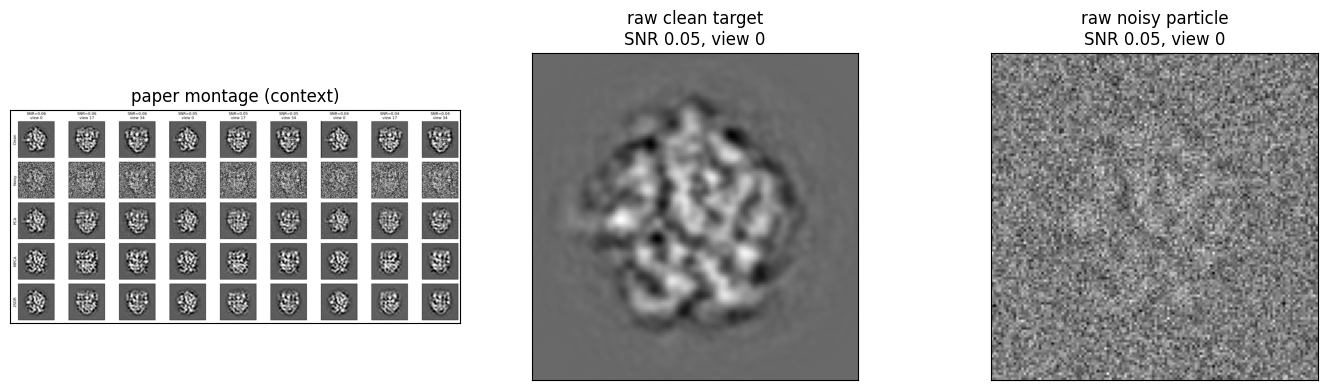

In [10]:
montage = Image.open(
    REPO_ROOT / "results" / "seventy-s-same-sample" / "paper_montage.png"
).convert("RGB")
montage.thumbnail((1200, 600))
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].imshow(montage)
axes[0].set_title("paper montage (context)")
axes[1].imshow(clean_70s, cmap="gray")
axes[1].set_title("raw clean target\nSNR 0.05, view 0")
axes[2].imshow(noisy_70s, cmap="gray")
axes[2].set_title("raw noisy particle\nSNR 0.05, view 0")
for axis in axes:
    axis.set_xticks([])
    axis.set_yticks([])
fig.tight_layout()


max |API - Q.T X Q|:   1.373e-14
max round-trip error:  2.498e-16
spatial squared norm:  205.266397
Z squared norm:        205.266397


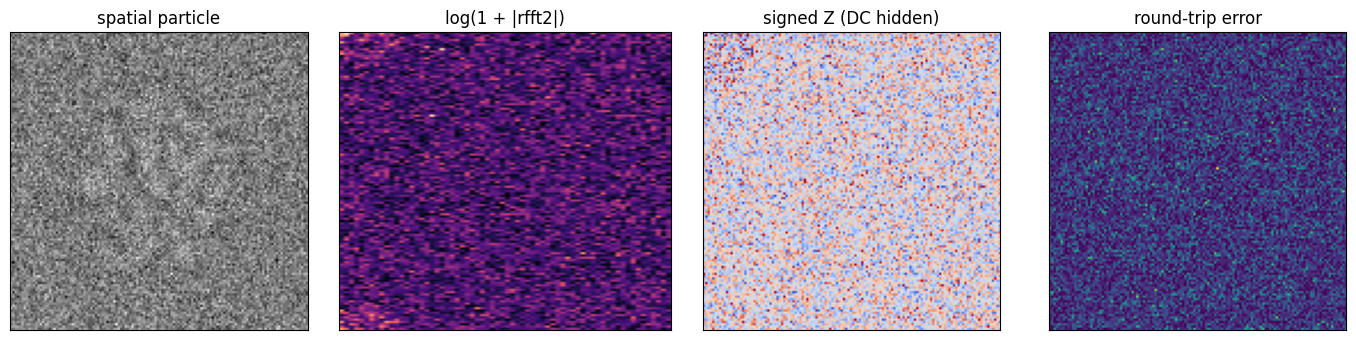

In [11]:
Q130 = real_fourier_basis(130, dtype=torch.float64)
Z_70s_dense = Q130.T @ noisy_70s @ Q130
Z_70s = real_fourier_transform(noisy_70s)
recovered_70s = real_fourier_inverse(Z_70s)

torch.testing.assert_close(
    Z_70s, Z_70s_dense, atol=2e-10, rtol=2e-10
)
torch.testing.assert_close(
    recovered_70s, noisy_70s, atol=2e-10, rtol=2e-10
)
torch.testing.assert_close(
    Z_70s.square().sum(),
    noisy_70s.square().sum(),
    atol=2e-8,
    rtol=2e-12,
)

print(
    f"max |API - Q.T X Q|:   "
    f"{float((Z_70s - Z_70s_dense).abs().max()):.3e}"
)
print(
    f"max round-trip error:  "
    f"{float((recovered_70s - noisy_70s).abs().max()):.3e}"
)
print(
    f"spatial squared norm:  "
    f"{float(noisy_70s.square().sum()):.9g}"
)
print(f"Z squared norm:        {float(Z_70s.square().sum()):.9g}")

half_70s = torch.fft.rfft2(noisy_70s, norm="ortho")
Z_display = Z_70s.clone()
Z_display[0, 0] = 0.0
z_limit = float(
    torch.quantile(Z_display.abs().flatten(), 0.99)
)

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
axes[0].imshow(noisy_70s, cmap="gray")
axes[0].set_title("spatial particle")
axes[1].imshow(
    torch.log1p(half_70s.abs()), cmap="magma", aspect="auto"
)
axes[1].set_title("log(1 + |rfft2|)")
axes[2].imshow(
    Z_display,
    cmap="coolwarm",
    vmin=-z_limit,
    vmax=z_limit,
)
axes[2].set_title("signed Z (DC hidden)")
axes[3].imshow(
    (recovered_70s - noisy_70s).abs(), cmap="viridis"
)
axes[3].set_title("round-trip error")
for axis in axes:
    axis.set_xticks([])
    axis.set_yticks([])
fig.tight_layout()


## 6. A minimal fixed-rank 2SDR bridge

We now take 64 noisy SNR 0.05 particles, map them to complete
$130\times130$ real Fourier matrices, fit fixed ranks
$(p,q,r)=(4,4,4)$, and invert the reconstructed coordinates. Clean
targets are used only for the descriptive display and MSE below; they
are not used to fit the model.

These ranks and this 64-particle subset are chosen for a fast classroom
example. They are not the paper's selected ranks and should not be used
to interpret the paper's method comparison.


fixed ranks:             (4, 4, 4)
iterations/converged:    58/True
descriptive noisy MSE:   0.0116793
descriptive 2SDR MSE:    0.000508387


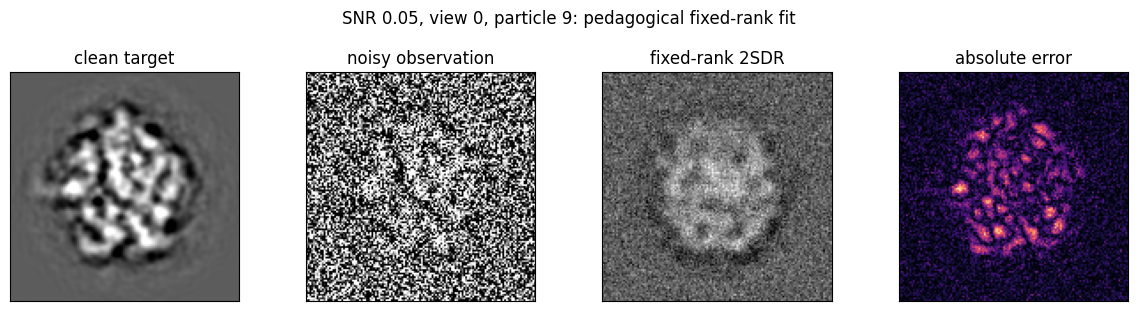

In [12]:
batch_size = 64
noisy_batch = torch.from_numpy(
    np.array(noisy_stack[:batch_size], copy=True)
).to(torch.float32)
clean_batch = torch.from_numpy(
    np.array(clean_stack[:batch_size], copy=True)
).to(torch.float32)

coordinates = real_fourier_transform(noisy_batch)
fit = fit_2sdr(
    coordinates, (4, 4, 4), max_iter=100, tol=1e-5
)
reconstructed_coordinates = fit.reconstruct(coordinates)
reconstructed_images = real_fourier_inverse(
    reconstructed_coordinates
)

assert fit.converged
assert reconstructed_images.shape == noisy_batch.shape

noisy_mse = float(
    (noisy_batch - clean_batch).square().mean()
)
reconstruction_mse = float(
    (reconstructed_images - clean_batch).square().mean()
)
print(f"fixed ranks:             {fit.ranks}")
print(
    f"iterations/converged:    "
    f"{fit.iterations}/{fit.converged}"
)
print(f"descriptive noisy MSE:   {noisy_mse:.6g}")
print(f"descriptive 2SDR MSE:    {reconstruction_mse:.6g}")

example = particle_index
lower, upper = torch.quantile(
    clean_batch[example], torch.tensor([0.01, 0.99])
)
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
panels = (
    (clean_batch[example], "clean target"),
    (noisy_batch[example], "noisy observation"),
    (reconstructed_images[example], "fixed-rank 2SDR"),
    (
        (
            reconstructed_images[example]
            - clean_batch[example]
        ).abs(),
        "absolute error",
    ),
)
for axis, (panel, title) in zip(axes, panels):
    if title == "absolute error":
        axis.imshow(panel, cmap="magma")
    else:
        axis.imshow(
            panel,
            cmap="gray",
            vmin=float(lower),
            vmax=float(upper),
        )
    axis.set_title(title)
    axis.set_xticks([])
    axis.set_yticks([])
fig.suptitle(
    "SNR 0.05, view 0, particle 9: pedagogical fixed-rank fit",
    y=1.02,
)
fig.tight_layout()


## What you should retain

- rfft2 is a storage-efficient half spectrum, not yet the square real
  matrix used by 2SDR.
- Fixed conjugate-pair blocks retain phase and remove only forced
  Hermitian redundancy.
- The implementation and construction agree:
  $\operatorname{real\_fourier\_transform}(X)=Q_h^TXQ_w$.
- The map is orthogonal, so it preserves Frobenius norm, white-noise
  covariance, and exact invertibility up to numerical precision.
- Fourier 2SDR receives the signed real matrix $Z$, not a magnitude
  spectrum.
- You can use the tested transform before mastering every parity case.
  A deeper derivation becomes necessary when changing FFT conventions,
  masks, frequency weights, CTF corrections, or covariance assumptions.
